# Lab 1 — Reconstruct a Synthetic Patient’s Data Journey
**AI in Healthcare · B.Tech AI, third year · 120 minutes**

Companion: `session-06-data-ecosystem.md`.

You will inspect healthcare records, define row meanings, audit quality, link tables, construct a cohort, parse FHIR JSON, and visualize time. Prerequisites: basic Python and tables; pandas examples are provided.

All records are invented. They are teaching examples, not clinical evidence or a representative population. This lab trains no model and requires no downloads, credentials, or real patient data.

**How to work:** Run cells in order. Complete each **Student response** and exercise cell. Reference answers are at the end. Submit this notebook with outputs and your interpretations. The generated files go to `healthcare_ecosystem_lab_data/`; rerunning the generator recreates only its named teaching files.

**Schedule:** setup/inventory 15 min; quality/dictionary 20; linkage 25; cohort 20; FHIR 20; plots 15; reflection 5.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("healthcare_ecosystem_lab_data")
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
print("Teaching files:", DATA.resolve())

Teaching files: /kaggle/working/healthcare_ecosystem_lab_data


If imports fail, install `pandas` and `matplotlib` in your notebook environment (for example, `%pip install pandas matplotlib` in a separate cell), then rerun. No package installation is performed automatically.

In [2]:
patients = pd.DataFrame([
    ("P001", 1980), ("P002", 1992), ("P003", 1975), ("P004", 2000)
], columns=["patient_id", "birth_year"])
encounters = pd.DataFrame([
    ("E001", "P001", "2026-01-10T09:00:00+05:30", "outpatient"),
    ("E002", "P001", "2026-02-10T10:00:00+05:30", "outpatient"),
    ("E003", "P002", "2026-01-15T11:00:00+05:30", "outpatient"),
    ("E004", "P003", "2026-01-20T09:00:00+05:30", "outpatient"),
    ("E005", "P003", "2026-03-01T09:00:00+05:30", "outpatient"),
    ("E006", "P004", "2025-12-20T09:00:00+05:30", "outpatient")
], columns=["encounter_id", "patient_id", "start", "type"])
observations = pd.DataFrame([
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O002", "E001", "temperature", 37, "Cel", "2026-01-10T09:12:00+05:30"),
    ("O003", "E002", "heart_rate", None, "beats/min", "2026-02-10T10:10:00+05:30"),
    ("O004", "E003", "temperature", 98.6, "[degF]", "2026-01-15T11:10:00+05:30"),
    ("O005", "E004", "heart_rate", 84, "beats/min", "2026-01-20T09:10:00+05:30"),
    ("O006", "E005", "heart_rate", 80, "beats/min", "2026-03-01T09:10:00+05:30")
], columns=["observation_id", "encounter_id", "code", "value", "unit", "effective_time"])
notes = pd.DataFrame([
    ("N001", "P001", "E001", "No history of diabetes. Patient reports reduced activity."),
    ("N002", "P001", "E002", "Follow-up visit. Further assessment planned."),
    ("N003", "P002", "E003", "Family history of diabetes; patient history not established.")
], columns=["note_id", "patient_id", "encounter_id", "text"])
times = pd.date_range("2026-01-10T00:00:00+05:30", periods=24, freq="h")
wearable = pd.DataFrame({"patient_id": "P001", "time": times,
                         "steps": [0,0,0,0,0,20,100,250,300,150,80,120,
                                   200,180,90,140,220,400,350,200,100,40,10,0]})
# Deliberately omit six expected hourly samples. A gap is not a zero.
wearable = wearable.drop(index=range(12,18)).reset_index(drop=True)
for name, frame in {"patients":patients, "encounters":encounters,
                    "observations":observations, "notes":notes, "wearable":wearable}.items():
    frame.to_csv(DATA / f"{name}.csv", index=False)

# Small R4-style collection Bundle, separate from the intentionally messy CSV.
# Educational examples; no formal FHIR/profile validator is run here.
resources = [{"resourceType":"Patient", "id":p} for p in patients.patient_id]
for row in encounters.itertuples():
    resources.append({"resourceType":"Encounter", "id":row.encounter_id,
        "status":"finished", "class":{"system":"http://terminology.hl7.org/CodeSystem/v3-ActCode",
        "code":"AMB"}, "subject":{"reference":f"Patient/{row.patient_id}"},
        "period":{"start":row.start}})
for oid, pid, eid, value, time in [
    ("O001","P001","E001",78,"2026-01-10T09:10:00+05:30"),
    ("O005","P003","E004",84,"2026-01-20T09:10:00+05:30")]:
    resources.append({"resourceType":"Observation", "id":oid, "status":"final",
        "code":{"coding":[{"system":"http://loinc.org", "code":"8867-4", "display":"Heart rate"}]},
        "subject":{"reference":f"Patient/{pid}"},
        "encounter":{"reference":f"Encounter/{eid}"}, "effectiveDateTime":time,
        "valueQuantity":{"value":value, "unit":"beats/minute",
        "system":"http://unitsofmeasure.org", "code":"/min"}})
bundle = {"resourceType":"Bundle", "type":"collection", "entry":[
    {"fullUrl":f"https://example.org/fhir/{r['resourceType']}/{r['id']}", "resource":r}
    for r in resources]}
(DATA / "patient_bundle.json").write_text(json.dumps(bundle, indent=2), encoding="utf-8")
print("Created five CSV files and one JSON file.")

Created five CSV files and one JSON file.


## 1. Inventory (0–15 minutes)
Load the generated files as if another team had supplied them. Identify the meaning of one row in each table. Are these sources, representations, or both?


In [3]:
tables = {name: pd.read_csv(DATA / f"{name}.csv")
          for name in ["patients", "encounters", "observations", "notes", "wearable"]}

for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))
    
patients, encounters, observations, notes, wearable = [tables[n] for n in tables]
encounters["start"] = pd.to_datetime(encounters["start"], utc=True)
observations["effective_time"] = pd.to_datetime(observations["effective_time"], utc=True)
wearable["time"] = pd.to_datetime(wearable["time"], utc=True)

patients (4, 2)


,patient_id,birth_year
0,P001,1980
1,P002,1992
2,P003,1975


encounters (6, 4)


,encounter_id,patient_id,start,type
0,E001,P001,2026-01-10T09:00:00+05:30,outpatient
1,E002,P001,2026-02-10T10:00:00+05:30,outpatient
2,E003,P002,2026-01-15T11:00:00+05:30,outpatient


observations (7, 6)


,observation_id,encounter_id,code,value,unit,effective_time
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
1,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
2,O002,E001,temperature,37.0,Cel,2026-01-10T09:12:00+05:30


notes (3, 4)


,note_id,patient_id,encounter_id,text
0,N001,P001,E001,No history of diabetes. Patient reports reduce...
1,N002,P001,E002,Follow-up visit. Further assessment planned.
2,N003,P002,E003,Family history of diabetes; patient history no...


wearable (18, 3)


,patient_id,time,steps
0,P001,2026-01-10 00:00:00+05:30,0
1,P001,2026-01-10 01:00:00+05:30,0
2,P001,2026-01-10 02:00:00+05:30,0


**Student response:**

- **patients:** one row per synthetic person; `patient_id` is the identifier. It is a structured table useful for person-level attributes such as birth year.
- **encounters:** one row per visit; `encounter_id` identifies the visit and `patient_id` links it to a person. It can support visit timelines and cohort selection.
- **observations:** one row per measurement record; `observation_id` identifies it and `encounter_id` links it to a visit. Code, value, unit, and time give the measurement meaning.
- **notes:** one row per note; `note_id` identifies the note, while patient and encounter IDs provide links. The CSV still has unstructured text because the note content is free-form language, not a set of coded fields.
- **wearable:** one row per supplied hourly activity sample, identified by patient and time. It can be used to plot activity over time.

These are structured tabular representations of synthetic source records. The fixture does not represent other possible lecture sources such as device/vendor systems, laboratory systems, claims, or external clinical documents unless explicitly added.

In [4]:
print("Exact duplicate observation rows:", observations.duplicated().sum())
print("Repeated observation IDs:", observations.observation_id.duplicated().sum())
display(observations.isna().sum().rename("missing_count").to_frame())
display(observations.groupby(["code", "unit"]).size().rename("rows").reset_index())
display(notes.assign(keyword_diabetes=notes.text.str.contains("diabetes", case=False)))

Exact duplicate observation rows: 1
Repeated observation IDs: 1


,missing_count
observation_id,0
encounter_id,0
code,0
value,1
unit,0
effective_time,0


,code,unit,rows
0,heart_rate,beats/min,5
1,temperature,Cel,1
2,temperature,[degF],1


,note_id,patient_id,encounter_id,text,keyword_diabetes
0,N001,P001,E001,No history of diabetes. Patient reports reduce...,True
1,N002,P001,E002,Follow-up visit. Further assessment planned.,False
2,N003,P002,E003,Family history of diabetes; patient history no...,True


In [5]:
# Exercise: create a dictionary with at least eight rows across three files.
data_dictionary = pd.DataFrame([
    ("patients", "patient_id", "Synthetic identifier for a person", "string", "not applicable", "primary key", "Not expected to be missing in this fixture"),
    ("patients", "birth_year", "Year of birth", "integer", "year", "attribute", "Not specified as missing in this fixture"),
    ("encounters", "encounter_id", "Unique identifier for a visit", "string", "not applicable", "primary key", "Not expected to be missing in this fixture"),
    ("encounters", "patient_id", "Person associated with the visit", "string", "not applicable", "foreign key to patients.patient_id", "Missing value would prevent patient linkage"),
    ("encounters", "start", "Start time of the visit", "datetime with timezone", "timestamp", "event time", "Missing value would prevent time-window cohort selection"),
    ("observations", "observation_id", "Identifier for a recorded measurement", "string", "not applicable", "observation key in this fixture", "Repeated IDs require checking for exact duplicates or conflicts"),
    ("observations", "value", "Numeric measurement value", "numeric", "depends on code and unit", "measurement", "Missing means value was not supplied; it is not zero"),
    ("observations", "unit", "Unit used for the measurement", "string", "unit code/label", "measurement metadata", "Missing unit makes interpretation/conversion uncertain"),
    ("observations", "effective_time", "Time the observation applies to", "datetime with timezone", "timestamp", "event time", "Missing time complicates temporal analysis"),
    ("notes", "text", "Free-text clinical note", "string", "not applicable", "unstructured content", "Missing text would mean note content is unavailable"),
    ("wearable", "steps", "Steps in the hourly interval", "integer", "steps per interval", "measurement", "Absent timestamp is a gap, not evidence of zero steps"),
], columns=["file", "column", "meaning", "type", "unit", "key_role", "missing_meaning"])
display(data_dictionary)

# Convert temperatures in a copy, preserving original value and unit for auditability.
temperature_source = observations.drop_duplicates().copy()
temperature_answer = temperature_source.loc[temperature_source.code.eq("temperature")].copy()
assert temperature_answer.unit.isin(["Cel", "[degF]"]).all()
temperature_answer["value_celsius"] = temperature_answer.apply(
    lambda r: (r.value - 32) * 5 / 9 if r.unit == "[degF]" else r.value, axis=1)
display(temperature_answer)


,file,column,meaning,type,unit,key_role,missing_meaning
0,patients,patient_id,Synthetic identifier for a person,string,not applicable,primary key,Not expected to be missing in this fixture
1,patients,birth_year,Year of birth,integer,year,attribute,Not specified as missing in this fixture
2,encounters,encounter_id,Unique identifier for a visit,string,not applicable,primary key,Not expected to be missing in this fixture
3,encounters,patient_id,Person associated with the visit,string,not applicable,foreign key to patients.patient_id,Missing value would prevent patient linkage
4,encounters,start,Start time of the visit,datetime with timezone,timestamp,event time,Missing value would prevent time-window cohort...
5,observations,observation_id,Identifier for a recorded measurement,string,not applicable,observation key in this fixture,Repeated IDs require checking for exact duplic...
6,observations,value,Numeric measurement value,numeric,depends on code and unit,measurement,Missing means value was not supplied; it is no...
7,observations,unit,Unit used for the measurement,string,unit code/label,measurement metadata,Missing unit makes interpretation/conversion u...
8,observations,effective_time,Time the observation applies to,datetime with timezone,timestamp,event time,Missing time complicates temporal analysis
9,notes,text,Free-text clinical note,string,not applicable,unstructured content,Missing text would mean note content is unavai...


,observation_id,encounter_id,code,value,unit,effective_time,value_celsius
2,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,37.0
4,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,37.0


**Student response:** Four issues are: (1) an exact duplicate observation row, (2) a missing heart-rate value, (3) temperature values recorded in Celsius and Fahrenheit, and (4) note wording that can mislead a simple keyword search. The wearable table also has six missing hourly samples. Keyword matching is unreliable because the word “diabetes” can appear in a negated statement (“No history of diabetes”) or in family history rather than as a patient diagnosis. I would remove a repeated observation only after confirming it is an exact duplicate caused by an export/process issue, using identifiers and relevant fields. If the same ID has conflicting values or times, I would investigate rather than delete it automatically.

In [6]:
clean_obs = observations.drop_duplicates().copy()
assert clean_obs.observation_id.is_unique
assert patients.patient_id.is_unique
assert encounters.encounter_id.is_unique
print("Raw rows:", len(observations), "After exact deduplication:", len(clean_obs))

Raw rows: 7 After exact deduplication: 6


## 3. Link records without changing their meaning (35–60 minutes)
First attach each encounter to a patient, then attach each observation to its encounter. `validate="many_to_one"` checks that the right-hand keys are unique. The merge indicator checks whether references matched; cardinality validation alone does not check that.


In [7]:
encounter_patient = encounters.merge(patients, on="patient_id", how="left",
                                      validate="many_to_one", indicator=True)
assert encounter_patient["_merge"].eq("both").all()
encounter_patient = encounter_patient.drop(columns="_merge")
linked = clean_obs.merge(encounter_patient, on="encounter_id", how="left",
                         validate="many_to_one", indicator=True)
assert linked["_merge"].eq("both").all()
assert len(linked) == len(clean_obs)
linked = linked.drop(columns="_merge")
display(linked)
print("Rows:", len(linked), "Distinct patients:", linked.patient_id.nunique())

,observation_id,encounter_id,code,value,unit,effective_time,patient_id,start,type,birth_year
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10 03:40:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
1,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
2,O003,E002,heart_rate,NaN,beats/min,2026-02-10 04:40:00+00:00,P001,2026-02-10 04:30:00+00:00,outpatient,1980
3,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,P002,2026-01-15 05:30:00+00:00,outpatient,1992
4,O005,E004,heart_rate,84.0,beats/min,2026-01-20 03:40:00+00:00,P003,2026-01-20 03:30:00+00:00,outpatient,1975
5,O006,E005,heart_rate,80.0,beats/min,2026-03-01 03:40:00+00:00,P003,2026-03-01 03:30:00+00:00,outpatient,1975


Rows: 6 Distinct patients: 3


In [8]:
# Demonstrate multiplication by linking independent encounter and note rows only by patient.
bad_join = encounters.merge(notes[["patient_id", "note_id"]], on="patient_id", how="left")
display(bad_join.loc[bad_join.patient_id.eq("P001"), ["patient_id", "encounter_id", "note_id"]])

# Correctly link notes to the encounter they describe.
correct_notes = encounters.merge(notes[["encounter_id", "note_id", "text"]],
                                on="encounter_id", how="left", validate="one_to_many")
display(correct_notes.loc[correct_notes.patient_id.eq("P001"),
                         ["patient_id", "encounter_id", "note_id", "text"]])
print("P001 rows in patient-only join:", len(bad_join.loc[bad_join.patient_id.eq("P001")]))
print("P001 rows in encounter-linked join:", len(correct_notes.loc[correct_notes.patient_id.eq("P001")]))
assert len(bad_join.loc[bad_join.patient_id.eq("P001")]) == 4
assert len(correct_notes.loc[correct_notes.patient_id.eq("P001")]) == 2


,patient_id,encounter_id,note_id
0,P001,E001,N001
1,P001,E001,N002
2,P001,E002,N001
3,P001,E002,N002


,patient_id,encounter_id,note_id,text
0,P001,E001,N001,No history of diabetes. Patient reports reduce...
1,P001,E002,N002,Follow-up visit. Further assessment planned.


P001 rows in patient-only join: 4
P001 rows in encounter-linked join: 2


**Student response:** One row of `linked` represents one deduplicated observation connected to its encounter and patient. The patient table has four people, but `linked` contains observations for only three; P004 has an encounter but no observation record. To retain every patient, start with `patients` and use left joins, while remembering that the result may have one row per patient, encounter, or observation depending on the joins. The demonstration join is incorrect because it joins notes to visits only by patient ID, pairing each of P001’s visits with both of that patient’s notes. Joining on `encounter_id` links each note to the correct visit and avoids those false combinations.

In [9]:
window_start = pd.Timestamp("2026-01-01", tz="Asia/Kolkata").tz_convert("UTC")
window_end = pd.Timestamp("2026-03-01", tz="Asia/Kolkata").tz_convert("UTC")
# Select visits in the half-open interval, then count distinct visits per patient.
eligible_encounters = encounters.loc[
    encounters.start.ge(window_start) & encounters.start.lt(window_end)
].copy()
cohort_counts = eligible_encounters.groupby("patient_id").encounter_id.nunique()
cohort = cohort_counts[cohort_counts.ge(2)].rename("encounter_count").reset_index()
display(eligible_encounters[["patient_id", "encounter_id", "start"]])
display(cohort)
print("Included patient IDs:", cohort.patient_id.tolist())


,patient_id,encounter_id,start
0,P001,E001,2026-01-10 03:30:00+00:00
1,P001,E002,2026-02-10 04:30:00+00:00
2,P002,E003,2026-01-15 05:30:00+00:00
3,P003,E004,2026-01-20 03:30:00+00:00


,patient_id,encounter_count
0,P001,2


Included patient IDs: ['P001']


**Student response:** The cohort includes **P001**, with two distinct encounters between 1 January 2026 (inclusive) and 1 March 2026 (exclusive). P003 is excluded because the second encounter starts exactly on 1 March, which is the excluded end boundary; only one of P003’s visits falls inside the interval. Counting observation rows after a join would not reliably count visits because a visit can have multiple observations, and some visits may have none. This is a record-availability cohort based on encounter counts and dates, not a disease cohort, so it does not establish disease status or disease risk.

In [10]:
bundle_loaded = json.loads((DATA / "patient_bundle.json").read_text(encoding="utf-8"))
resource_index = {f"{e['resource']['resourceType']}/{e['resource']['id']}": e["resource"]
                  for e in bundle_loaded["entry"]}
fhir_rows = []
for resource in resource_index.values():
    if resource["resourceType"] != "Observation":
        continue
    patient_ref = resource["subject"]["reference"]
    encounter_ref = resource["encounter"]["reference"]
    assert patient_ref in resource_index and encounter_ref in resource_index
    assert resource_index[encounter_ref]["subject"]["reference"] == patient_ref
    coding = next(c for c in resource["code"]["coding"] if c["system"] == "http://loinc.org")
    q = resource["valueQuantity"]
    fhir_rows.append({"observation_id":resource["id"],
        "patient_id":patient_ref.split("/")[-1], "encounter_id":encounter_ref.split("/")[-1],
        "loinc_code":coding["code"], "value":q["value"], "ucum_code":q["code"],
        "effective_time":resource["effectiveDateTime"]})
fhir_frame = pd.DataFrame(fhir_rows)
fhir_frame["effective_time"] = pd.to_datetime(fhir_frame["effective_time"], utc=True)
display(fhir_frame)

,observation_id,patient_id,encounter_id,loinc_code,value,ucum_code,effective_time
0,O001,P001,E001,8867-4,78,/min,2026-01-10 03:40:00+00:00
1,O005,P003,E004,8867-4,84,/min,2026-01-20 03:40:00+00:00


In [11]:
# Explicit mappings apply only to the codes/units in this teaching fixture.
comparison_source = linked.copy()
comparison_source["loinc_code"] = comparison_source.code.map({"heart_rate":"8867-4"})
comparison_source["ucum_code"] = comparison_source.unit.map({"beats/min":"/min"})
comparison = fhir_frame.merge(comparison_source, on="observation_id", how="left",
                              suffixes=("_fhir", "_csv"), validate="one_to_one", indicator=True)
assert comparison["_merge"].eq("both").all()
for field in ["patient_id", "encounter_id", "loinc_code", "value", "ucum_code", "effective_time"]:
    assert comparison[f"{field}_fhir"].eq(comparison[f"{field}_csv"]).all(), field
print("All two FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.")

All two FHIR observations agree with their CSV counterparts on identity, code, value, unit, and time.


**Student response:** In the JSON, an Observation’s `subject.reference` points to a Patient (for example, `Patient/P001`) and `encounter.reference` points to an Encounter (for example, `Encounter/E001`). The coding system is LOINC, and the quantity contains a numeric `value` and coded unit. We compared coded units rather than display labels because labels can vary in wording, while codes are intended to provide a more consistent machine-readable meaning. The FHIR bundle contains only two observations, while the CSV contains more records, so the bundle is a subset. Matching selected identity, code, value, unit, and time fields confirms agreement for those records only; it does not prove the data are complete, formally FHIR-valid, or clinically valid.

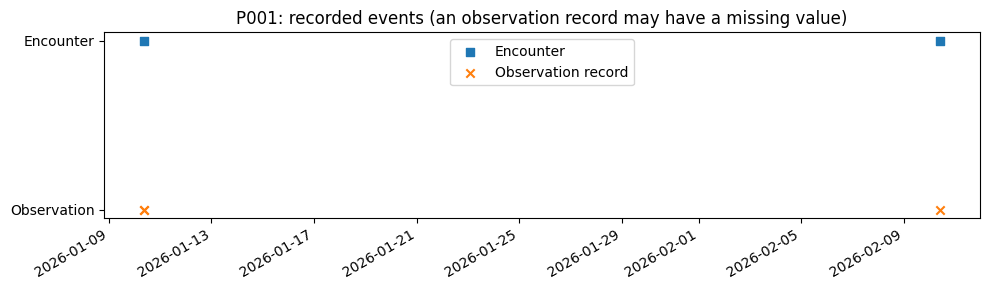

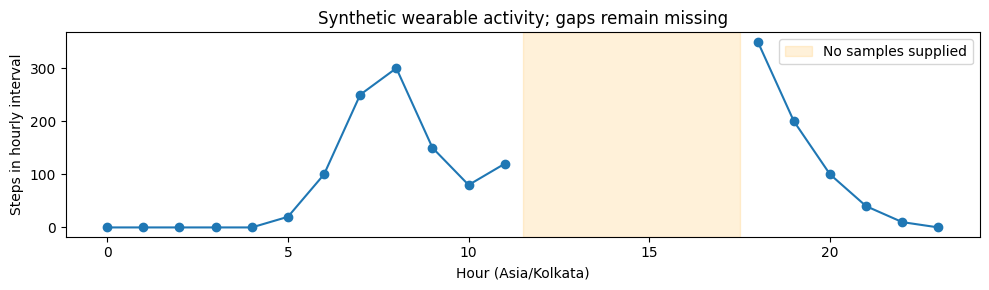

Missing expected hourly samples: 6


In [12]:
p1_encounters = encounters.loc[encounters.patient_id.eq("P001")]
p1_obs = linked.loc[linked.patient_id.eq("P001")]
fig, ax = plt.subplots(figsize=(10, 3))
ax.scatter(p1_encounters.start.dt.tz_convert("Asia/Kolkata"), [1]*len(p1_encounters), label="Encounter", marker="s")
ax.scatter(p1_obs.effective_time.dt.tz_convert("Asia/Kolkata"), [0]*len(p1_obs), label="Observation record", marker="x")
ax.set_yticks([0, 1], ["Observation", "Encounter"])
ax.set_title("P001: recorded events (an observation record may have a missing value)")
ax.legend(loc="upper center")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

expected = pd.date_range("2026-01-10", periods=24, freq="h", tz="Asia/Kolkata")
series = wearable.set_index("time")["steps"].tz_convert("Asia/Kolkata").reindex(expected)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(series.index.hour, series.values, marker="o")
ax.axvspan(11.5, 17.5, alpha=0.15, color="orange", label="No samples supplied")
ax.set(xlabel="Hour (Asia/Kolkata)", ylabel="Steps in hourly interval", title="Synthetic wearable activity; gaps remain missing")
ax.legend()
plt.tight_layout()
plt.show()
print("Missing expected hourly samples:", series.isna().sum())

**Student response:** The orange region marks six hourly timestamps for which no wearable samples were supplied. Replacing these gaps with zero would falsely suggest that the patient recorded no steps during those hours, even though the data are simply absent. O003 still appears on the timeline because an observation record exists and has an effective timestamp, even though its numeric value is missing. The time of a record and the availability of its measurement value are separate pieces of information.

In [13]:
temperature_answer = clean_obs.loc[clean_obs.code.eq("temperature")].copy()
assert temperature_answer.unit.isin(["Cel", "[degF]"]).all()
temperature_answer["value_celsius"] = temperature_answer.apply(
    lambda r: (r.value - 32) * 5 / 9 if r.unit == "[degF]" else r.value, axis=1)
display(temperature_answer)

correct_notes_answer = encounters.merge(notes[["encounter_id", "note_id", "text"]],
                                        on="encounter_id", how="left", validate="one_to_many")
assert len(correct_notes_answer.loc[correct_notes_answer.patient_id.eq("P001")]) == 2

eligible_answer = encounters.loc[encounters.start.ge(window_start) & encounters.start.lt(window_end)]
counts_answer = eligible_answer.groupby("patient_id").encounter_id.nunique()
cohort_answer = counts_answer[counts_answer.ge(2)].rename("encounter_count").reset_index()
display(cohort_answer)
assert cohort_answer.patient_id.tolist() == ["P001"]
assert len(clean_obs) == 6
assert linked.patient_id.nunique() == 3
assert series.isna().sum() == 6
print("Reference checks passed.")

,observation_id,encounter_id,code,value,unit,effective_time,value_celsius
2,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,37.0
4,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,37.0


,patient_id,encounter_count
0,P001,2


Reference checks passed.


### Final reflection (student response)

Flattening FHIR observations into a table can lose resource context such as status, full references, coding-system details, and relationships to other resources. It can also hide optional fields and differences between a missing field and a missing measurement unless these are handled explicitly.

Before training a model, I would consider at least three limitations. First, this is a tiny synthetic dataset and is not representative of real patients, so it cannot support reliable performance or prevalence claims. Second, the data contain quality problems such as duplicate rows, missing values, inconsistent measurement units, and missing wearable timestamps. Third, the notes are free text and simple keyword matching can confuse negation or family history with a patient diagnosis. I would also check linkage errors, sampling bias, privacy, and whether the labels are suitable for the intended task.

If a prediction is made at encounter start, measurements recorded ten minutes later would not yet be available and must not be used as input features. Using them would create temporal leakage and make the model appear better than it would be in practice. A real system may also need a data-availability or ingestion timestamp, because the time a measurement was taken (`effective_time`) may differ from when it reached the system and became available for prediction.